In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from scipy.stats import norm, probplot
from scipy.optimize import brentq
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
import xgboost as xgb

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
np.random.seed(42)

## 0. Configuration

Everything that used to be hard-coded lives here. `ASSET_FILES` drives the whole notebook: add an
entry per asset and the multi-asset experiments switch on automatically.

In [3]:
DATA_DIR = '/content/drive/MyDrive/data_files/2021-2026'
BOND_FILE = f"{DATA_DIR}/bond_yield.csv"

# ---- assets -------------------------------------------------------------
# Add / remove entries here. Set the NIFTY paths to enable Exp 9-12.
ASSET_FILES = {
    'BANKNIFTY': {
        'options': f"{DATA_DIR}/banknifty2021-2026.csv",
        'spot':    f"{DATA_DIR}/BankNifty_Spot.csv",
    },
    'NIFTY50': {
        'options': f"{DATA_DIR}/Nifty2021-2026.csv",
        'spot':    f"{DATA_DIR}/Nifty_Spot.csv",
    },
}

# ---- filtering / binning constants (paper values) -----------------------
LOOKBACK      = 20      # trading days of underlying history
DTE_MIN       = 3       # days to maturity, lower bound
DTE_MAX       = 45      # days to maturity, upper bound
ATM_BAND      = 0.04    # |1 - S/K| <= 0.04  (near-ATM filter)
W_BIN         = 0.1     # bin width on the 100*C/K scale
NUM_CLASSES   = 50      # number of output bins (last one is an overflow bin)
TRAIN_FRAC    = 0.70    # linear (time-ordered) train/test split
SEED          = 42

# ---- model hyperparameters (Appendix A of the paper) -------------------
ANN_LR, ANN_BATCH, ANN_EPOCHS, ANN_PATIENCE = 0.00012, 32, 150, 15
XGB_ROUNDS, XGB_DEPTH, XGB_LR = 100, 3, 0.3

# ---- regime-shift (stress) test window, Exp 14 -------------------------
# Paper used Jan 2019 - Apr 2020 (COVID crash). Set to any window inside your data,
# or leave as None to use the final 20% of the timeline automatically.
STRESS_START = None     # e.g. '2025-01-01'
STRESS_END   = None     # e.g. '2025-12-31'

OPTION_TYPE = 'CE'      # European-style CALL options only, as in the paper

print("Assets configured:", list(ASSET_FILES))

Assets configured: ['BANKNIFTY', 'NIFTY50']


## 1. Data pipeline (Table 2)

The original linear cleaning code is refactored into `build_asset_dataset()` so it can be run once
per asset. Logic is unchanged: drop untraded rows, keep 3-45 DTE, keep near-ATM contracts, require a
previous-day close for the same contract, and attach 20 days of underlying OHLC history plus the
bond yield.

In [4]:
def load_bond_yields(path):
    bonds = pd.read_csv(path)
    bonds.columns = ['date', 'risk_free_rate', 'rf_open', 'rf_high', 'rf_low', 'change_pct']
    bonds['date'] = pd.to_datetime(bonds['date'], errors='coerce')
    for c in ['risk_free_rate', 'rf_open', 'rf_high', 'rf_low']:
        bonds[c] = pd.to_numeric(bonds[c].astype(str).str.replace(',', ''), errors='coerce')

    # sentinel / bad prints (the ">50%" rows) are masked then forward filled
    bonds.loc[bonds['risk_free_rate'] > 50, 'risk_free_rate'] = np.nan
    bonds = bonds.dropna(subset=['date']).sort_values('date')
    bonds['risk_free_rate'] = bonds['risk_free_rate'].ffill().bfill()

    # reindex to every calendar day so option dates always find a rate
    full = pd.date_range(bonds['date'].min(), bonds['date'].max(), freq='D')
    out = (bonds.set_index('date')[['risk_free_rate']]
                .reindex(full).rename_axis('date').ffill().reset_index())
    return out


def load_spot(path):
    spot = pd.read_csv(path)
    spot.columns = ['date', 'spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']
    spot['date'] = pd.to_datetime(spot['date'], errors='coerce')
    for c in ['spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']:
        spot[c] = pd.to_numeric(spot[c].astype(str).str.replace(',', ''), errors='coerce')
    return spot.dropna(subset=['date']).sort_values('date').reset_index(drop=True)


def load_options(path):
    opt = pd.read_csv(path).drop(columns=['Unnamed: 0'], errors='ignore')
    opt.columns = ['symbol', 'date', 'expiry', 'option_type', 'strike',
                   'open', 'high', 'low', 'close', 'ltp', 'settle_price',
                   'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
                   'open_interest', 'change_in_oi', 'underlying']
    opt['date'] = pd.to_datetime(opt['date'], format='%d-%b-%Y', errors='coerce')
    opt['expiry'] = pd.to_datetime(opt['expiry'], format='%d-%b-%Y', errors='coerce')
    num_cols = ['strike', 'open', 'high', 'low', 'close', 'ltp', 'settle_price', 'contracts',
                'turnover_lakhs', 'premium_turnover_lakhs', 'open_interest', 'change_in_oi',
                'underlying']
    for c in num_cols:
        opt[c] = pd.to_numeric(opt[c].astype(str).str.replace(',', ''), errors='coerce')
    opt['option_type'] = opt['option_type'].str.strip().str.upper()
    return opt.dropna(subset=['date', 'expiry', 'strike'])


def build_lookback_frame(spot, lookback=LOOKBACK):
    lb = spot[['date', 'spot_open', 'spot_high', 'spot_low', 'spot_close']].copy()
    for lag in range(1, lookback + 1):
        lb[f'und_open_lag{lag}']  = lb['spot_open'].shift(lag)
        lb[f'und_high_lag{lag}']  = lb['spot_high'].shift(lag)
        lb[f'und_low_lag{lag}']   = lb['spot_low'].shift(lag)
        lb[f'und_close_lag{lag}'] = lb['spot_close'].shift(lag)
    return lb.drop(columns=['spot_open', 'spot_high', 'spot_low', 'spot_close']).dropna().reset_index(drop=True)


def build_asset_dataset(name, files, bonds, verbose=True):
    counts = {}
    opt = load_options(files['options'])
    counts['raw'] = len(opt)

    spot = load_spot(files['spot'])

    # underlying close from the spot file (authoritative), not the options file
    opt = opt.merge(spot[['date', 'spot_close']], on='date', how='left')
    opt['underlying'] = opt['spot_close']
    opt = opt.drop(columns=['spot_close']).dropna(subset=['underlying'])

    # calls only
    if OPTION_TYPE is not None:
        opt = opt[opt['option_type'] == OPTION_TYPE]

    # traded contracts only
    opt = opt[(opt['contracts'].fillna(0) > 0) & (opt['turnover_lakhs'].fillna(0) > 0)]

    # time to maturity window
    opt['days_to_expiry'] = (opt['expiry'] - opt['date']).dt.days
    opt = opt[(opt['days_to_expiry'] >= DTE_MIN) & (opt['days_to_expiry'] <= DTE_MAX)]

    # near-ATM filter
    opt['moneyness_gap'] = (1 - opt['underlying'] / opt['strike']).abs()
    opt = opt[opt['moneyness_gap'] <= ATM_BAND]

    # previous-day close of the *same* contract
    opt = opt.sort_values(['expiry', 'option_type', 'strike', 'date'])
    opt['prev_day_close'] = opt.groupby(['expiry', 'option_type', 'strike'])['close'].shift(1)
    opt = opt.dropna(subset=['prev_day_close'])

    # 20-day underlying OHLC history + spot + risk free rate
    opt = opt.merge(build_lookback_frame(spot), on='date', how='inner')
    opt = opt.merge(spot, on='date', how='left')
    opt = opt.merge(bonds, on='date', how='left')
    opt['risk_free_rate'] = opt['risk_free_rate'].ffill().bfill()
    opt['time_to_maturity_yrs'] = opt['days_to_expiry'] / 365.0
    opt['asset'] = name

    opt = opt.sort_values('date').reset_index(drop=True)
    counts['filtered'] = len(opt)

    if verbose:
        print(f"[{name}] raw={counts['raw']:,}  filtered={counts['filtered']:,}  "
              f"({opt['date'].min().date()} to {opt['date'].max().date()})")
    return opt, counts

In [5]:
bonds = load_bond_yields(BOND_FILE)

DATA, COUNTS = {}, {}
for name, files in ASSET_FILES.items():
    DATA[name], COUNTS[name] = build_asset_dataset(name, files, bonds)

MULTI_ASSET = len(DATA) >= 2
print("\nMulti-asset experiments enabled:", MULTI_ASSET)

[BANKNIFTY] raw=656,347  filtered=95,238  (2021-01-04 to 2026-06-25)
[NIFTY50] raw=708,909  filtered=126,566  (2021-01-04 to 2026-07-07)

Multi-asset experiments enabled: True


## 2. Output variable: binning (Fig. 6)

Output is the scale-free ratio 100·C/K, mapped into equispaced bins of width `W_BIN`. Anything above
bin `NUM_CLASSES-1` is collapsed into a single overflow bin, exactly as in the original code.

In [6]:
def add_bins(df, w=W_BIN, num_classes=NUM_CLASSES):
    df = df.copy()
    df['output_ratio'] = 100 * df['close'] / df['strike']
    df['bin_label_raw'] = np.ceil(df['output_ratio'] / w).astype(int).clip(lower=1)
    df['bin_label'] = np.where(df['bin_label_raw'] > num_classes - 1, num_classes, df['bin_label_raw'])
    return df

for name in DATA:
    DATA[name] = add_bins(DATA[name])
    d = DATA[name]
    print(f"[{name}] bin range {d['bin_label'].min()}-{d['bin_label'].max()}, "
          f"overflow rows: {(d['bin_label'] == NUM_CLASSES).sum():,} "
          f"({100*(d['bin_label']==NUM_CLASSES).mean():.2f}%)")

[BANKNIFTY] bin range 1-50, overflow rows: 1,316 (1.38%)
[NIFTY50] bin range 1-50, overflow rows: 420 (0.33%)


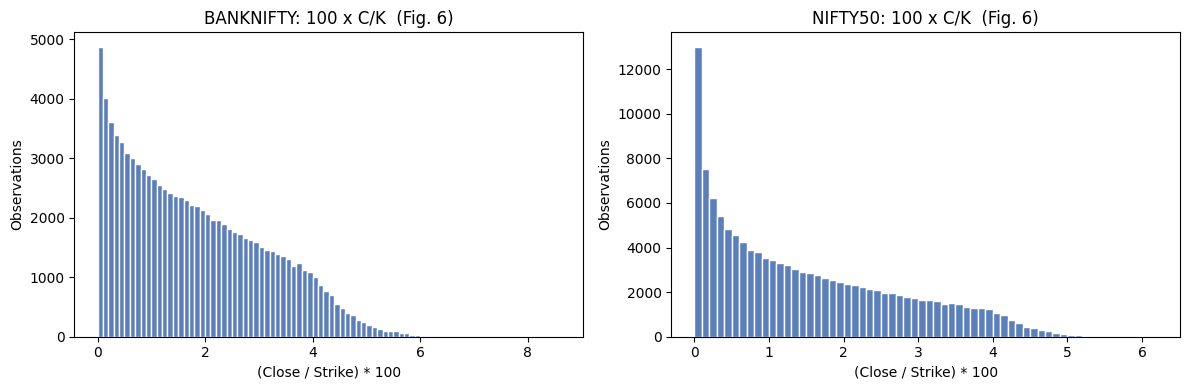

In [7]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6*len(DATA), 4), squeeze=False)
for ax, (name, d) in zip(axes[0], DATA.items()):
    ax.hist(d['output_ratio'], bins=np.arange(0, d['output_ratio'].max()+W_BIN, W_BIN),
            color='#5b7fbd', edgecolor='white')
    ax.set_title(f'{name}: 100 x C/K  (Fig. 6)')
    ax.set_xlabel('(Close / Strike) * 100'); ax.set_ylabel('Observations')
plt.tight_layout(); plt.show()

## 3. Feature sets — Approaches I, II, III (Table 3)

* **Approach I** — 19 order statistics of Close log returns + moneyness, time to maturity, rate (22).
* **Approach II** — means and signed-root covariance entries of OHLC log returns + the same 3 (17).
* **Approach III** — Approach II plus scaled previous option price and mean moneyness (19).

In [8]:
def log_returns_from_lookback(df, field, lookback=LOOKBACK):
    cols_chrono = [f'und_{field}_lag{i}' for i in range(lookback, 0, -1)]
    prices = df[cols_chrono].values.astype(float)
    return np.diff(np.log(prices), axis=1)


def signed_sqrt(x):
    out = np.zeros_like(x)
    mask = x != 0
    out[mask] = x[mask] / np.sqrt(np.abs(x[mask]))
    return out


# contract-level features shared by all three approaches
def contract_block(df):
    return pd.DataFrame({
        'moneyness':        (df['underlying'] / df['strike']).values,
        'time_to_maturity': df['days_to_expiry'].values.astype(float),
        'interest_rate':    df['risk_free_rate'].values.astype(float),
    }, index=df.index)


def build_approach1(df):
    lr_close = log_returns_from_lookback(df, 'close')
    os_close = np.sort(lr_close, axis=1)
    X = pd.DataFrame(os_close, columns=[f'os_close_{i+1}' for i in range(os_close.shape[1])],
                     index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach2(df):
    lr_o = log_returns_from_lookback(df, 'open')
    lr_h = log_returns_from_lookback(df, 'high')
    lr_l = log_returns_from_lookback(df, 'low')
    lr_c = log_returns_from_lookback(df, 'close')

    stack = np.stack([lr_o, lr_h, lr_l, lr_c], axis=1)
    centered = stack - stack.mean(axis=2, keepdims=True)
    cov = np.einsum('nik,njk->nij', centered, centered) / (stack.shape[2] - 1)
    cov_t = signed_sqrt(cov)

    labels = ['O', 'H', 'L', 'C']
    cov_cols = {f'cov_{labels[i]}{labels[j]}': cov_t[:, i, j]
                for i in range(4) for j in range(i + 1)}

    X = pd.DataFrame({'mu_O': lr_o.mean(axis=1), 'mu_H': lr_h.mean(axis=1),
                      'mu_L': lr_l.mean(axis=1), 'mu_C': lr_c.mean(axis=1), **cov_cols},
                     index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach3(df):
    X = build_approach2(df).drop(columns=['bin_label'])
    X['prev_option_price_scaled'] = (df['prev_day_close'] / df['strike']).values
    lookback_close_cols = [f'und_close_lag{i}' for i in range(1, LOOKBACK + 1)]
    X['mean_moneyness'] = (df[lookback_close_cols].mean(axis=1) / df['strike']).values
    X['bin_label'] = df['bin_label'].values
    return X


APPROACH_BUILDERS = {'Approach I': build_approach1,
                     'Approach II': build_approach2,
                     'Approach III': build_approach3}

In [9]:
FEATURES = {name: {ap: fn(d) for ap, fn in APPROACH_BUILDERS.items()}
            for name, d in DATA.items()}

overview = pd.DataFrame({
    ap: {name: FEATURES[name][ap].shape[1] - 1 for name in FEATURES}
    for ap in APPROACH_BUILDERS
})
print("Feature counts per approach (Table 3):")
print(overview)

Feature counts per approach (Table 3):
           Approach I  Approach II  Approach III
BANKNIFTY          22           17            19
NIFTY50            22           17            19


## 4. Train / test split (Table 2) and evaluation metrics (Eqs. 4-6)

Split is linear in time at `TRAIN_FRAC` of unique trading dates, since the observations are not
independent.

In [10]:
SPLIT = {}
for name, d in DATA.items():
    dates = np.sort(d['date'].unique())
    cutoff = dates[int(len(dates) * TRAIN_FRAC) - 1]
    tr = (d['date'] <= cutoff).values
    te = (d['date'] > cutoff).values
    SPLIT[name] = {'train': tr, 'test': te, 'cutoff': pd.Timestamp(cutoff)}
    COUNTS[name].update(train=int(tr.sum()), test=int(te.sum()))
    print(f"[{name}] cutoff {pd.Timestamp(cutoff).date()} | train {tr.sum():,} | test {te.sum():,}")

print("\nTable 2 equivalent:")
print(pd.DataFrame(COUNTS).loc[['raw', 'filtered', 'train', 'test']])

[BANKNIFTY] cutoff 2024-11-07 | train 76,505 | test 18,733
[NIFTY50] cutoff 2024-11-11 | train 79,485 | test 47,081

Table 2 equivalent:
          BANKNIFTY  NIFTY50
raw          656347   708909
filtered      95238   126566
train         76505    79485
test          18733    47081


In [11]:
def error_metric_EM(actual_bins, predicted_bins, bin_width=W_BIN):
    # Eq. (5): bin-width scaled mean absolute bin distance -> MAE as w -> 0
    return bin_width * np.mean(np.abs(np.asarray(actual_bins, float) - np.asarray(predicted_bins, float)))

def inaccuracy_metric_rho(actual_bins, predicted_bins):
    # Eq. (6): P(|C_i - P_i| > 2), i.e. actual bin falls outside the 5-bin predicted band
    return np.mean(np.abs(np.asarray(actual_bins, float) - np.asarray(predicted_bins, float)) > 2)

def accuracy_metric_A(actual_bins, predicted_bins):
    # Eq. (4): plain classification accuracy (shown for contrast; not the paper's main metric)
    return np.mean(np.round(np.asarray(predicted_bins, float)) == np.asarray(actual_bins, float))

## 5. Models

`fit_bundle` returns the fitted scaler plus both models so that a model trained on one asset can
later be applied to another asset's test set (Experiments 10, 11, 14) without retraining.

In [12]:
def train_ann(X_tr, y_tr_idx, X_val, y_val_idx, num_classes, seed=SEED):
    tf.random.set_seed(seed)
    ann = keras.Sequential([
        keras.layers.Input(shape=(X_tr.shape[1],)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(num_classes, activation='softmax'),
    ])
    ann.compile(optimizer=keras.optimizers.Adam(learning_rate=ANN_LR),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=ANN_PATIENCE,
                                       restore_best_weights=True, verbose=0)
    ann.fit(X_tr, y_tr_idx, validation_data=(X_val, y_val_idx),
            epochs=ANN_EPOCHS, batch_size=ANN_BATCH, callbacks=[es], verbose=0)
    return ann


def train_xgb(X_tr, y_tr_idx, X_val, y_val_idx, num_classes, seed=SEED):
    dtrain = xgb.DMatrix(X_tr, label=y_tr_idx)
    dval = xgb.DMatrix(X_val, label=y_val_idx)
    params = {'objective': 'multi:softprob', 'num_class': num_classes,
              'max_depth': XGB_DEPTH, 'learning_rate': XGB_LR,
              'eval_metric': 'mlogloss', 'seed': seed}
    return xgb.train(params, dtrain, num_boost_round=XGB_ROUNDS,
                     evals=[(dtrain, 'train'), (dval, 'val')],
                     early_stopping_rounds=10, verbose_eval=0)


def fit_bundle(X_tr, y_tr, X_val, y_val, num_classes=NUM_CLASSES, seed=SEED, models=('ann', 'xgb')):
    scaler = StandardScaler().fit(X_tr)
    Xs_tr, Xs_val = scaler.transform(X_tr), scaler.transform(X_val)
    bundle = {'scaler': scaler, 'num_classes': num_classes, 'columns': None}
    if 'ann' in models:
        bundle['ann'] = train_ann(Xs_tr, y_tr - 1, Xs_val, y_val - 1, num_classes, seed)
    if 'xgb' in models:
        bundle['xgb'] = train_xgb(Xs_tr, y_tr - 1, Xs_val, y_val - 1, num_classes, seed)
    return bundle


def predict_bins(bundle, X, model='ann'):
    Xs = bundle['scaler'].transform(X)
    if model == 'ann':
        return bundle['ann'].predict(Xs, verbose=0).argmax(axis=1) + 1
    booster = bundle['xgb']
    d = xgb.DMatrix(Xs)
    return booster.predict(d, iteration_range=(0, booster.best_iteration + 1)).argmax(axis=1) + 1


def split_xy(feat_df, mask):
    cols = [c for c in feat_df.columns if c != 'bin_label']
    return feat_df.loc[mask, cols].values, feat_df.loc[mask, 'bin_label'].values, cols

## Experiment 1 — Single-asset models (Tables 4 and 5)

One ANN and one XGBoost per approach per asset. Fitted bundles and test predictions are cached in
`BUNDLES` / `PREDS` and reused by every later experiment.

In [13]:
BUNDLES, PREDS = {}, {}

for name in DATA:
    tr, te = SPLIT[name]['train'], SPLIT[name]['test']
    for ap, feat in FEATURES[name].items():
        X_tr, y_tr, cols = split_xy(feat, tr)
        X_te, y_te, _ = split_xy(feat, te)

        bundle = fit_bundle(X_tr, y_tr, X_te, y_te)
        bundle['columns'] = cols
        BUNDLES[(name, ap)] = bundle

        PREDS[(name, ap)] = {
            'y_true': y_te,
            'ann': predict_bins(bundle, X_te, 'ann'),
            'xgb': predict_bins(bundle, X_te, 'xgb'),
        }
        print(f"trained: {name} / {ap}")

trained: BANKNIFTY / Approach I
trained: BANKNIFTY / Approach II
trained: BANKNIFTY / Approach III
trained: NIFTY50 / Approach I
trained: NIFTY50 / Approach II
trained: NIFTY50 / Approach III


In [14]:
rows = []
for (name, ap), p in PREDS.items():
    rows.append({'asset': name, 'approach': ap,
                 'EM_ANN': error_metric_EM(p['y_true'], p['ann']),
                 'EM_XGB': error_metric_EM(p['y_true'], p['xgb']),
                 'rho_ANN': inaccuracy_metric_rho(p['y_true'], p['ann']),
                 'rho_XGB': inaccuracy_metric_rho(p['y_true'], p['xgb'])})

single_asset_results = (pd.DataFrame(rows)
                        .set_index(['asset', 'approach'])
                        .round(3)
                        .sort_index())
print("=== Tables 4 / 5: single-asset models (lower is better) ===")
print(single_asset_results)

=== Tables 4 / 5: single-asset models (lower is better) ===
                        EM_ANN  EM_XGB  rho_ANN  rho_XGB
asset     approach                                      
BANKNIFTY Approach I     0.344   0.305    0.461    0.392
          Approach II    0.305   0.276    0.434    0.357
          Approach III   0.245   0.187    0.356    0.257
NIFTY50   Approach I     0.190   0.152    0.279    0.199
          Approach II    0.193   0.168    0.298    0.224
          Approach III   0.157   0.135    0.221    0.174


## Experiment 2 — Averaging ensemble (Tables 6 and 7)

Predictions of the ANN and the XGBoost model for the same approach are averaged. As the paper notes
(Remark 5.1), the ensemble prediction can be a half-integer; the metrics need no modification.

In [15]:
rows = []
for (name, ap), p in PREDS.items():
    ens = (p['ann'] + p['xgb']) / 2
    p['ensemble'] = ens
    rows.append({'asset': name, 'approach': ap,
                 'EM': error_metric_EM(p['y_true'], ens),
                 'rho': inaccuracy_metric_rho(p['y_true'], ens)})

ensemble_results = pd.DataFrame(rows).set_index(['asset', 'approach']).round(3).sort_index()
print("=== Tables 6 / 7: averaging ensemble ===")
print(ensemble_results)

print("\nEM improvement of ensemble over the better single model:")
cmp = single_asset_results[['EM_ANN', 'EM_XGB']].min(axis=1).rename('best_single_EM')
print(pd.concat([cmp, ensemble_results['EM'].rename('ensemble_EM')], axis=1)
        .assign(delta=lambda t: (t['ensemble_EM'] - t['best_single_EM']).round(3)))

=== Tables 6 / 7: averaging ensemble ===
                           EM    rho
asset     approach                  
BANKNIFTY Approach I    0.299  0.442
          Approach II   0.273  0.401
          Approach III  0.192  0.300
NIFTY50   Approach I    0.152  0.228
          Approach II   0.164  0.258
          Approach III  0.131  0.193

EM improvement of ensemble over the better single model:
                        best_single_EM  ensemble_EM  delta
asset     approach                                        
BANKNIFTY Approach I             0.305        0.299 -0.006
          Approach II            0.276        0.273 -0.003
          Approach III           0.187        0.192  0.005
NIFTY50   Approach I             0.152        0.152  0.000
          Approach II            0.168        0.164 -0.004
          Approach III           0.135        0.131 -0.004


## Experiment 3 — Black-Scholes benchmark

Historical volatility over the trailing 20 days is used to calibrate B-S, the B-S price is converted
to the same 100·C/K bin scale, and the identical EM / rho metrics are computed. This is the "B-S
pricing" row of Tables 4, 5, 9 and 11.

In [16]:
def black_scholes_call(S, K, T, r, sigma):
    S = np.asarray(S, float); K = np.asarray(K, float); T = np.asarray(T, float)
    r = np.asarray(r, float); sigma = np.asarray(sigma, float)
    T = np.clip(T, 1/365, None)
    sigma = np.clip(sigma, 1e-4, None)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def add_hist_vol(df):
    lr_close = log_returns_from_lookback(df, 'close')
    df = df.copy()
    df['hist_vol'] = lr_close.std(axis=1, ddof=1) * np.sqrt(252)
    return df


def price_to_bin(price, strike, w=W_BIN, num_classes=NUM_CLASSES):
    ratio = 100 * np.asarray(price, float) / np.asarray(strike, float)
    return np.clip(np.ceil(ratio / w), 1, num_classes).astype(int)


def bs_benchmark(df, mask):
    sub = add_hist_vol(df).loc[mask].copy()
    sub['bs_price'] = black_scholes_call(sub['underlying'], sub['strike'],
                                         sub['time_to_maturity_yrs'],
                                         sub['risk_free_rate'] / 100, sub['hist_vol'])
    sub['bs_bin'] = price_to_bin(sub['bs_price'], sub['strike'])
    actual = np.clip(sub['bin_label'].values, 1, NUM_CLASSES)
    return sub, {'EM': error_metric_EM(actual, sub['bs_bin'].values),
                 'rho': inaccuracy_metric_rho(actual, sub['bs_bin'].values)}


BS = {}
for name, d in DATA.items():
    DATA[name] = add_hist_vol(d)
    sub, metrics = bs_benchmark(DATA[name], SPLIT[name]['test'])
    BS[name] = {'frame': sub, **metrics}
    print(f"[{name}] Black-Scholes benchmark -> EM {metrics['EM']:.3f}, rho {metrics['rho']:.3f}")

bs_table = pd.DataFrame({k: {'EM': v['EM'], 'rho': v['rho']} for k, v in BS.items()}).T.round(3)
print("\n=== Black-Scholes benchmark by asset ===")
print(bs_table)

[BANKNIFTY] Black-Scholes benchmark -> EM 0.313, rho 0.470
[NIFTY50] Black-Scholes benchmark -> EM 0.222, rho 0.337

=== Black-Scholes benchmark by asset ===
              EM    rho
BANKNIFTY  0.313  0.470
NIFTY50    0.222  0.337


In [17]:
# side-by-side with the trained models (the full Table 4 / 5 layout)
for name in DATA:
    block = single_asset_results.loc[name][['EM_ANN', 'EM_XGB', 'rho_ANN', 'rho_XGB']]
    print(f"\n=== {name} contracts ===")
    print(f"B-S pricing : EM {BS[name]['EM']:.3f}   rho {BS[name]['rho']:.3f}")
    print(block)
    print(f"Ensemble    :\n{ensemble_results.loc[name]}")


=== BANKNIFTY contracts ===
B-S pricing : EM 0.313   rho 0.470
              EM_ANN  EM_XGB  rho_ANN  rho_XGB
approach                                      
Approach I     0.344   0.305    0.461    0.392
Approach II    0.305   0.276    0.434    0.357
Approach III   0.245   0.187    0.356    0.257
Ensemble    :
                 EM    rho
approach                  
Approach I    0.299  0.442
Approach II   0.273  0.401
Approach III  0.192  0.300

=== NIFTY50 contracts ===
B-S pricing : EM 0.222   rho 0.337
              EM_ANN  EM_XGB  rho_ANN  rho_XGB
approach                                      
Approach I     0.190   0.152    0.279    0.199
Approach II    0.193   0.168    0.298    0.224
Approach III   0.157   0.135    0.221    0.174
Ensemble    :
                 EM    rho
approach                  
Approach I    0.152  0.228
Approach II   0.164  0.258
Approach III  0.131  0.193


## Experiment 4 — Plain accuracy metric A (Eq. 4)

Included for completeness: the paper argues A is the wrong metric for an ordinal output with many
bins, because it treats a one-bin miss and a twenty-bin miss identically. The numbers below make
that point concretely against EM and rho.

In [18]:
rows = []
for (name, ap), p in PREDS.items():
    rows.append({'asset': name, 'approach': ap,
                 'A_ANN': accuracy_metric_A(p['y_true'], p['ann']),
                 'A_XGB': accuracy_metric_A(p['y_true'], p['xgb']),
                 'EM_ANN': error_metric_EM(p['y_true'], p['ann']),
                 'rho_ANN': inaccuracy_metric_rho(p['y_true'], p['ann'])})
print("=== Accuracy A vs EM / rho ===")
print(pd.DataFrame(rows).set_index(['asset', 'approach']).round(3).sort_index())

=== Accuracy A vs EM / rho ===
                        A_ANN  A_XGB  EM_ANN  rho_ANN
asset     approach                                   
BANKNIFTY Approach I    0.161  0.176   0.344    0.461
          Approach II   0.164  0.197   0.305    0.434
          Approach III  0.191  0.261   0.245    0.356
NIFTY50   Approach I    0.266  0.306   0.190    0.279
          Approach II   0.242  0.293   0.193    0.298
          Approach III  0.281  0.342   0.157    0.221


## Experiment 5 — EM vs bin width (Figs. 4 and 5)

The claim being tested: EM is asymptotically insensitive to binning, so the largest width at which
EM stabilises (the paper picks 0.1) is a defensible choice. Features are unchanged across widths —
only the labels and the number of classes move. XGBoost is used by default because this loop
retrains many times; set `MODEL_FOR_BINWIDTH='ann'` for the slower ANN version.

[BANKNIFTY] bin-width sweep done
[NIFTY50] bin-width sweep done


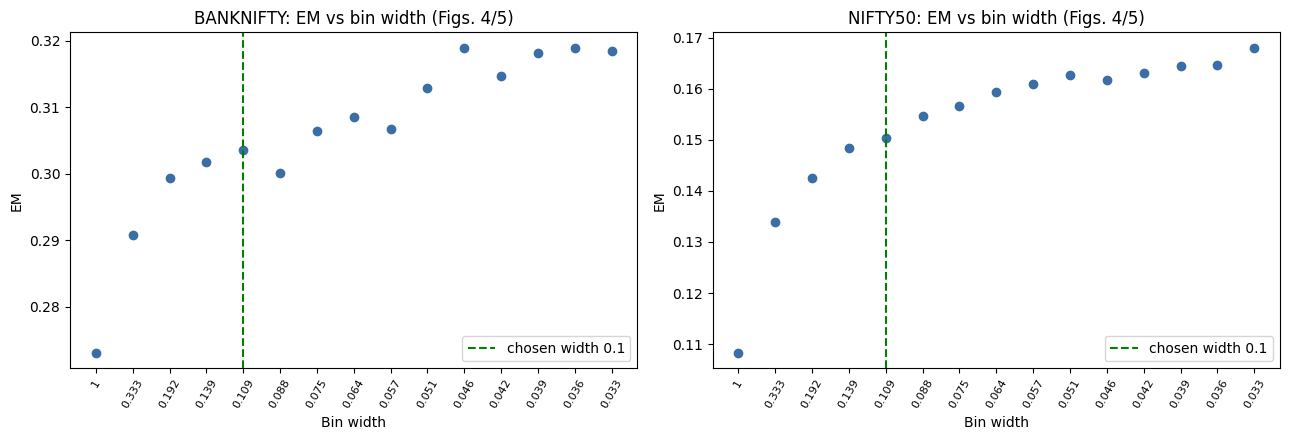


[BANKNIFTY]
 bin_width  n_classes     EM    rho
     1.000          6 0.2731 0.0000
     0.333         17 0.2908 0.0839
     0.192         29 0.2993 0.1977
     0.139         39 0.3017 0.2887
     0.109         50 0.3036 0.3692
     0.088         62 0.3001 0.4378
     0.075         73 0.3064 0.5009
     0.064         85 0.3085 0.5495
     0.057         95 0.3067 0.5841
     0.051        106 0.3129 0.6205
     0.046        118 0.3189 0.6556
     0.042        129 0.3147 0.6790
     0.039        139 0.3181 0.6968
     0.036        151 0.3190 0.7159
     0.033        164 0.3185 0.7297

[NIFTY50]
 bin_width  n_classes     EM    rho
     1.000          5 0.1083 0.0000
     0.333         15 0.1339 0.0059
     0.192         25 0.1425 0.0502
     0.139         35 0.1485 0.1114
     0.109         44 0.1503 0.1717
     0.088         55 0.1546 0.2432
     0.075         64 0.1565 0.2990
     0.064         75 0.1593 0.3590
     0.057         84 0.1609 0.4015
     0.051         94 0.1626 0.4441
    

In [19]:
MODEL_FOR_BINWIDTH = 'xgb'
BINWIDTH_APPROACH = 'Approach I'
BIN_WIDTHS = [1.0, 0.333, 0.192, 0.139, 0.109, 0.088, 0.075, 0.064, 0.057, 0.051, 0.046, 0.042, 0.039, 0.036, 0.033]


def em_for_binwidth(name, w, approach=BINWIDTH_APPROACH, model=MODEL_FOR_BINWIDTH, cover=0.995):
    d = DATA[name]
    ratio = 100 * d['close'] / d['strike']
    raw = np.ceil(ratio / w).astype(int).clip(lower=1)

    # cap classes so the tail does not create thousands of near-empty bins
    counts = raw.value_counts().sort_index()
    cum = counts.cumsum() / counts.sum()
    cutoff = int(cum[cum <= cover].index.max()) if (cum <= cover).any() else int(raw.max())
    y = np.where(raw > cutoff, cutoff + 1, raw)
    n_classes = int(y.max())

    feat = FEATURES[name][approach].drop(columns=['bin_label']).copy()
    tr, te = SPLIT[name]['train'], SPLIT[name]['test']
    X_tr, X_te = feat.loc[tr].values, feat.loc[te].values
    y_tr, y_te = y[tr], y[te]

    bundle = fit_bundle(X_tr, y_tr, X_te, y_te, num_classes=n_classes, models=(model,))
    pred = predict_bins(bundle, X_te, model)
    return {'bin_width': w, 'n_classes': n_classes,
            'EM': error_metric_EM(y_te, pred, bin_width=w),
            'rho': inaccuracy_metric_rho(y_te, pred)}


binwidth_results = {}
for name in DATA:
    rows = [em_for_binwidth(name, w) for w in BIN_WIDTHS]
    binwidth_results[name] = pd.DataFrame(rows)
    print(f"[{name}] bin-width sweep done")

fig, axes = plt.subplots(1, len(DATA), figsize=(6.5*len(DATA), 4.5), squeeze=False)
for ax, (name, res) in zip(axes[0], binwidth_results.items()):
    ax.plot(range(len(res)), res['EM'], 'o', color='#3b6ea5')
    ax.axvline(int(np.argmin(np.abs(res['bin_width'] - 0.1))), ls='--', color='green',
               label='chosen width 0.1')
    ax.set_xticks(range(len(res)))
    ax.set_xticklabels([f"{w:g}" for w in res['bin_width']], rotation=60, fontsize=8)
    ax.set_xlabel('Bin width'); ax.set_ylabel('EM')
    ax.set_title(f'{name}: EM vs bin width (Figs. 4/5)'); ax.legend()
plt.tight_layout(); plt.show()

for name, res in binwidth_results.items():
    print(f"\n[{name}]"); print(res.round(4).to_string(index=False))

## Experiment 6 — Empirical CDF and quantiles of C_i - P_i (Fig. 11)

Turns a bin prediction into a confidence statement: 1-rho is the confidence that the true bin sits
in [P-2, P+2], and the 2%/98% quantiles give the wider band the paper quotes.

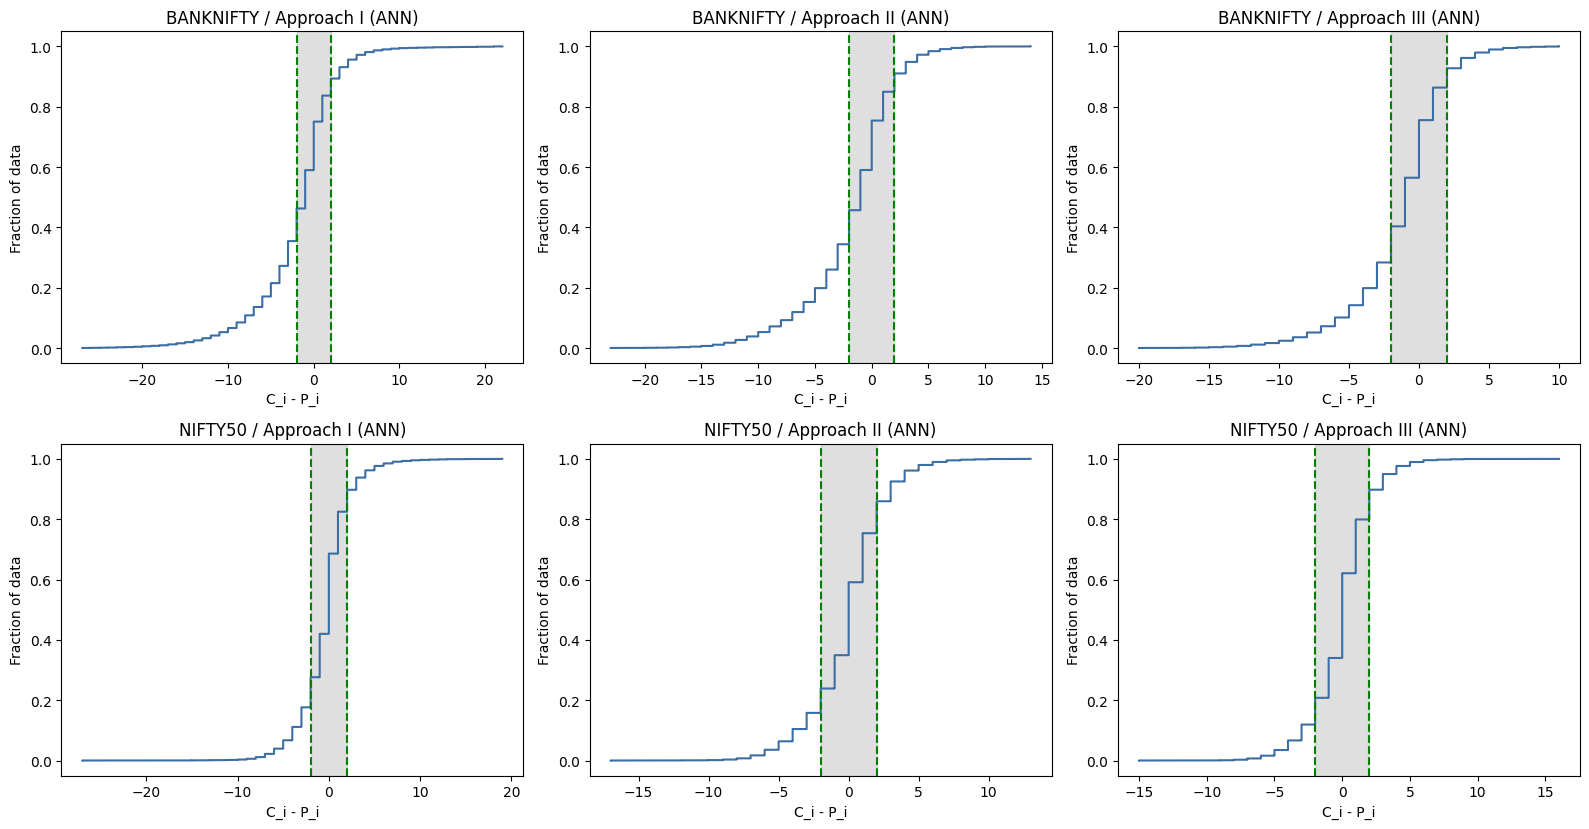

=== Fig. 11: quantiles of C_i - P_i and band coverage ===
                       model   q02  q25  median  q75  q98  P(|err|<=2)  P(|err|<=5)
asset     approach                                                                 
BANKNIFTY Approach I     ann -14.0 -4.0    -1.0  0.0  6.0        0.539        0.801
          Approach II    ann -12.0 -4.0    -1.0  0.0  5.0        0.566        0.832
          Approach III   ann -10.0 -3.0    -1.0  0.0  5.0        0.644        0.889
NIFTY50   Approach I     ann  -7.0 -2.0     0.0  1.0  6.0        0.721        0.937
          Approach II    ann  -6.0 -1.0     0.0  1.0  6.0        0.702        0.944
          Approach III   ann  -5.0 -1.0     0.0  1.0  5.0        0.779        0.974
BANKNIFTY / Approach I: actual bin within [P-2, P+2] with 54% confidence; within [P-5, P+5] with 80%.
BANKNIFTY / Approach II: actual bin within [P-2, P+2] with 57% confidence; within [P-5, P+5] with 83%.
BANKNIFTY / Approach III: actual bin within [P-2, P+2] with 64% c

In [20]:
def error_cdf_report(name, approach, model='ann', ax=None):
    p = PREDS[(name, approach)]
    err = np.asarray(p['y_true'], float) - np.asarray(p[model], float)
    q = np.percentile(err, [2, 25, 50, 75, 98])

    if ax is not None:
        xs = np.sort(err)
        ys = np.arange(1, len(xs)+1) / len(xs)
        ax.step(xs, ys, color='#3b6ea5')
        ax.axvline(-2, ls='--', color='green'); ax.axvline(2, ls='--', color='green')
        ax.axvspan(-2, 2, color='grey', alpha=0.25)
        ax.set_xlabel('C_i - P_i'); ax.set_ylabel('Fraction of data')
        ax.set_title(f'{name} / {approach} ({model.upper()})')

    within2 = np.mean(np.abs(err) <= 2)
    within5 = np.mean(np.abs(err) <= 5)
    return {'asset': name, 'approach': approach, 'model': model,
            'q02': q[0], 'q25': q[1], 'median': q[2], 'q75': q[3], 'q98': q[4],
            'P(|err|<=2)': within2, 'P(|err|<=5)': within5}


rows = []
fig, axes = plt.subplots(len(DATA), 3, figsize=(16, 4.2*len(DATA)), squeeze=False)
for i, name in enumerate(DATA):
    for j, ap in enumerate(APPROACH_BUILDERS):
        rows.append(error_cdf_report(name, ap, 'ann', axes[i][j]))
plt.tight_layout(); plt.show()

cdf_report = pd.DataFrame(rows).set_index(['asset', 'approach']).round(3)
print("=== Fig. 11: quantiles of C_i - P_i and band coverage ===")
print(cdf_report)

for _, r in cdf_report.reset_index().iterrows():
    print(f"{r['asset']} / {r['approach']}: actual bin within [P-2, P+2] with "
          f"{100*r['P(|err|<=2)']:.0f}% confidence; within [P-5, P+5] with "
          f"{100*r['P(|err|<=5)']:.0f}%.")

## Experiment 7 — Predicted IV band vs market-realized IV (Figs. 12 and 18)

The 5-bin predicted band around P is converted to a price interval, each end is inverted through
Black-Scholes into an implied volatility, and the daily-averaged band is compared with the
daily-averaged market-realized IV. The "band prediction error" is the fraction of days the realized
IV falls outside the band — the paper reports ~0.10 for 2018 and ~0.25 for the COVID period.

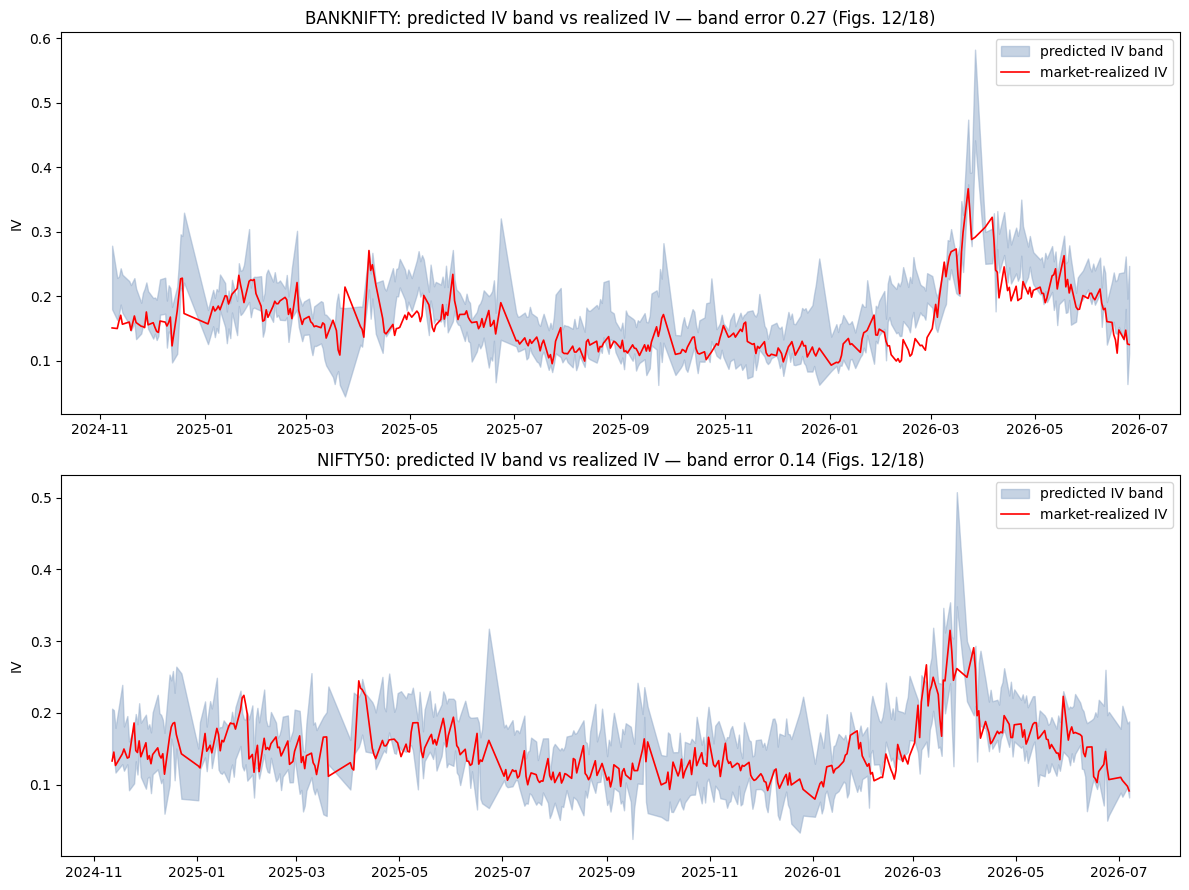

[BANKNIFTY] realized IV outside the predicted band on 26.9% of days (paper: ~10% in calm periods, ~25% in the COVID window)
[NIFTY50] realized IV outside the predicted band on 13.6% of days (paper: ~10% in calm periods, ~25% in the COVID window)


In [21]:
def implied_vol_call(price, S, K, T, r, lo=1e-4, hi=5.0):
    price, S, K, T, r = float(price), float(S), float(K), float(T), float(r)
    if not np.isfinite(price) or price <= 0 or T <= 0:
        return np.nan
    intrinsic = max(S - K * np.exp(-r * T), 0.0)
    if price <= intrinsic + 1e-8 or price >= S:
        return np.nan
    f = lambda s: float(black_scholes_call(S, K, T, r, s)) - price
    try:
        if f(lo) > 0 or f(hi) < 0:
            return np.nan
        return brentq(f, lo, hi, maxiter=200, xtol=1e-8)
    except Exception:
        return np.nan


def iv_series(prices, S, K, T, r):
    return np.array([implied_vol_call(p, s, k, t, rr)
                     for p, s, k, t, rr in zip(prices, S, K, T, r)])


def band_prices(pred_bins, strike, w=W_BIN, half_width=2):
    # bin n covers ((n-1)w, n w] on the 100*C/K scale
    pred = np.asarray(pred_bins, float)
    lo_ratio = np.clip((pred - half_width - 1) * w, 0, None)
    hi_ratio = (pred + half_width) * w
    return lo_ratio * strike / 100.0, hi_ratio * strike / 100.0


def iv_band_analysis(name, approach='Approach III', model='ann', max_rows=6000):
    d = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
    pred = PREDS[(name, approach)][model]

    if len(d) > max_rows:                      # keep the IV inversion tractable
        idx = np.linspace(0, len(d)-1, max_rows).astype(int)
        d, pred = d.iloc[idx].reset_index(drop=True), pred[idx]

    lo_px, hi_px = band_prices(pred, d['strike'].values)
    S, K = d['underlying'].values, d['strike'].values
    T, r = d['time_to_maturity_yrs'].values, d['risk_free_rate'].values / 100

    out = pd.DataFrame({
        'date': d['date'].values,
        'iv_market': iv_series(d['close'].values, S, K, T, r),
        'iv_lo': iv_series(lo_px, S, K, T, r),
        'iv_hi': iv_series(hi_px, S, K, T, r),
    })
    daily = out.groupby('date').mean(numeric_only=True).dropna()
    outside = ((daily['iv_market'] < daily['iv_lo']) | (daily['iv_market'] > daily['iv_hi'])).mean()
    return daily, outside


IV_BANDS = {}
fig, axes = plt.subplots(len(DATA), 1, figsize=(12, 4.5*len(DATA)), squeeze=False)
for ax, name in zip(axes[:, 0], DATA):
    daily, outside = iv_band_analysis(name)
    IV_BANDS[name] = {'daily': daily, 'band_error': outside}
    ax.fill_between(daily.index, daily['iv_lo'], daily['iv_hi'], color='#8fa8c8', alpha=0.5,
                    label='predicted IV band')
    ax.plot(daily.index, daily['iv_market'], color='red', lw=1.2, label='market-realized IV')
    ax.set_title(f'{name}: predicted IV band vs realized IV — band error {outside:.2f} (Figs. 12/18)')
    ax.set_ylabel('IV'); ax.legend()
plt.tight_layout(); plt.show()

for name, v in IV_BANDS.items():
    print(f"[{name}] realized IV outside the predicted band on {100*v['band_error']:.1f}% of days "
          f"(paper: ~10% in calm periods, ~25% in the COVID window)")

## Experiment 8 — Actual vs predicted price, identity line vs orthogonal regression (Fig. 14, Remark 5.2)

The predicted bin's midpoint is converted back to a price. If the orthogonal (total least squares)
regression line sits on top of the identity line, the model is neither systematically over- nor
under-pricing — the paper's empirical check for arbitrage-free pricing.

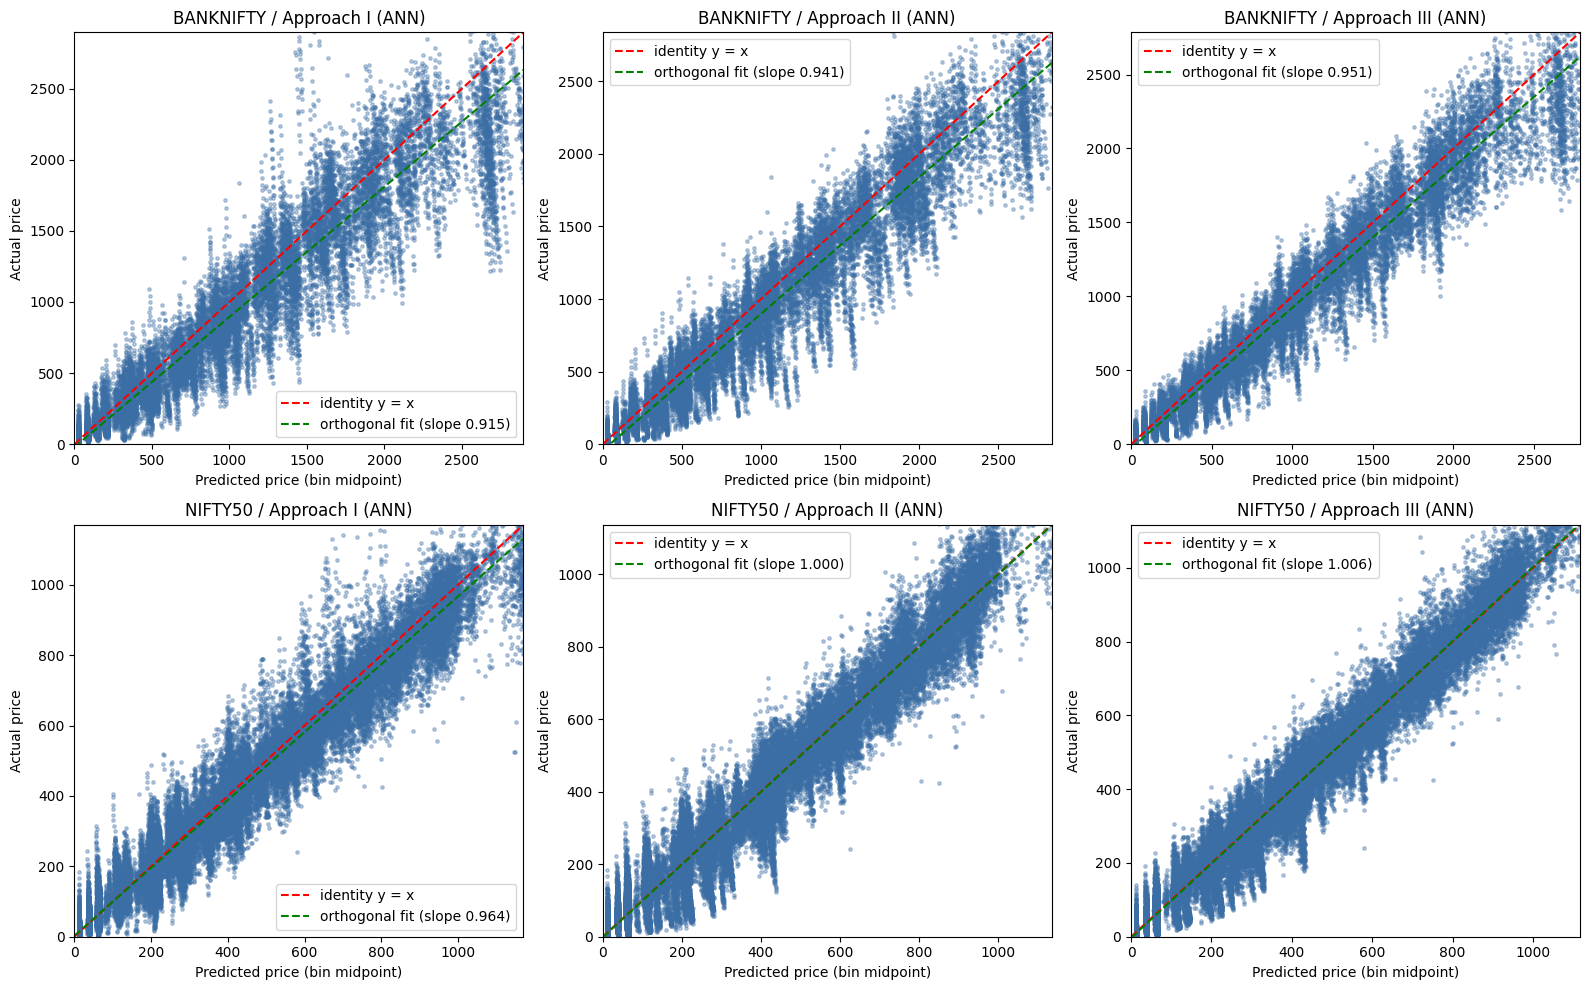

=== Remark 5.2: bias check (slope ~ 1 and intercept ~ 0 means no systematic mis-pricing) ===
                        tls_slope  tls_intercept  ols_slope  ols_intercept  mean_signed_error  MAE_price
asset     approach                                                                                      
BANKNIFTY Approach I       0.9153       -20.1337     0.8652        32.9212           109.7589   192.4102
          Approach II      0.9407       -42.4446     0.9010        -0.6859           104.9691   172.1265
          Approach III     0.9507       -27.4313     0.9235         0.4501            78.0919   138.5319
NIFTY50   Approach I       0.9640         3.0030     0.9424        10.8429            10.0413    47.1584
          Approach II      0.9999        -1.2855     0.9759         7.1954             1.3197    48.1456
          Approach III     1.0058        -3.1153     0.9891         2.7827             1.0739    39.4771
A TLS slope well above 1 with a negative intercept usually means th

In [22]:
def orthogonal_regression(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    xm, ym = x.mean(), y.mean()
    _, _, vt = np.linalg.svd(np.column_stack([x - xm, y - ym]), full_matrices=False)
    vx, vy = vt[0]
    slope = vy / vx
    return slope, ym - slope * xm


def bin_to_price(bins, strike, w=W_BIN):
    mid_ratio = (np.asarray(bins, float) - 0.5) * w     # midpoint of the bin
    return mid_ratio * np.asarray(strike, float) / 100.0


def actual_vs_predicted(name, approach='Approach III', model='ann', ax=None):
    d = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
    pred_px = bin_to_price(PREDS[(name, approach)][model], d['strike'].values)
    actual_px = d['close'].values

    slope, intercept = orthogonal_regression(pred_px, actual_px)
    if ax is not None:
        lim = np.nanpercentile(np.concatenate([pred_px, actual_px]), 99.5)
        ax.scatter(pred_px, actual_px, s=6, alpha=0.35, color='#3b6ea5')
        xs = np.linspace(0, lim, 100)
        ax.plot(xs, xs, 'r--', label='identity y = x')
        ax.plot(xs, slope * xs + intercept, 'g--', label=f'orthogonal fit (slope {slope:.3f})')
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_xlabel('Predicted price (bin midpoint)'); ax.set_ylabel('Actual price')
        ax.set_title(f'{name} / {approach} ({model.upper()})'); ax.legend()

    ols_slope, ols_int = np.polyfit(pred_px, actual_px, 1)
    return {'asset': name, 'approach': approach,
            'tls_slope': slope, 'tls_intercept': intercept,
            'ols_slope': ols_slope, 'ols_intercept': ols_int,
            'mean_signed_error': np.mean(pred_px - actual_px),
            'MAE_price': np.mean(np.abs(pred_px - actual_px))}


rows = []
fig, axes = plt.subplots(len(DATA), 3, figsize=(16, 5*len(DATA)), squeeze=False)
for i, name in enumerate(DATA):
    for j, ap in enumerate(APPROACH_BUILDERS):
        rows.append(actual_vs_predicted(name, ap, 'ann', axes[i][j]))
plt.tight_layout(); plt.show()

bias_report = pd.DataFrame(rows).set_index(['asset', 'approach']).round(4)
print("=== Remark 5.2: bias check (slope ~ 1 and intercept ~ 0 means no systematic mis-pricing) ===")
print(bias_report)
print("A TLS slope well above 1 with a negative intercept usually means the model is")
print("compressing its predictions toward the mean (undertrained), not mispricing;")
print("check mean_signed_error, which is the direct over/under-pricing measure.")

## Experiment 9 — Q-Q plot of the two assets' log returns (Fig. 13)

Motivates portability and combined training: the closer the two return distributions, the better a
model trained on one asset should transfer to the other.

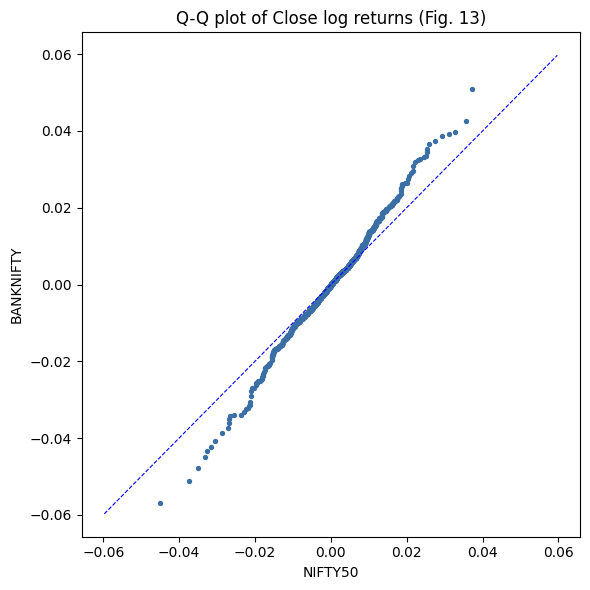

std BANKNIFTY: 0.1829 annualized
std NIFTY50: 0.1425 annualized


In [23]:
def asset_close_log_returns(name):
    spot = load_spot(ASSET_FILES[name]['spot'])
    s = spot['spot_close'].dropna().values
    return np.diff(np.log(s))


if MULTI_ASSET:
    names = list(DATA)[:2]
    a, b = asset_close_log_returns(names[0]), asset_close_log_returns(names[1])
    n = min(len(a), len(b))
    qa = np.quantile(a, np.linspace(0.001, 0.999, n))
    qb = np.quantile(b, np.linspace(0.001, 0.999, n))

    plt.figure(figsize=(6, 6))
    plt.scatter(qb, qa, s=8, color='#3b6ea5')
    lim = max(np.abs(np.concatenate([qa, qb]))) * 1.05
    plt.plot([-lim, lim], [-lim, lim], 'b--', lw=0.8)
    plt.xlabel(names[1]); plt.ylabel(names[0])
    plt.title('Q-Q plot of Close log returns (Fig. 13)')
    plt.tight_layout(); plt.show()

    print(f"std {names[0]}: {a.std(ddof=1)*np.sqrt(252):.4f} annualized")
    print(f"std {names[1]}: {b.std(ddof=1)*np.sqrt(252):.4f} annualized")
else:
    print("Skipped: needs two assets. Add a second entry to ASSET_FILES.")

## Experiment 10 — Asset portability (Table 8)

Every model trained on asset A is evaluated on asset B's test set, without retraining. The paper
finds NIFTY-trained models can beat BANKNIFTY-trained models on BANKNIFTY data.

In [24]:
portability_rows = []
if MULTI_ASSET:
    for src in DATA:
        for tgt in DATA:
            if src == tgt:
                continue
            te = SPLIT[tgt]['test']
            for ap in APPROACH_BUILDERS:
                feat = FEATURES[tgt][ap]
                X_te, y_te, _ = split_xy(feat, te)
                bundle = BUNDLES[(src, ap)]
                for model in ('ann', 'xgb'):
                    pred = predict_bins(bundle, X_te, model)
                    portability_rows.append({
                        'trained_on': src, 'tested_on': tgt, 'approach': ap, 'model': model.upper(),
                        'EM': error_metric_EM(y_te, pred),
                        'rho': inaccuracy_metric_rho(y_te, pred)})

    portability = (pd.DataFrame(portability_rows)
                   .pivot_table(index=['trained_on', 'tested_on', 'approach'],
                                columns='model', values=['EM', 'rho'])
                   .round(3))
    print("=== Table 8: cross-asset portability ===")
    print(portability)

    print("\nSame-asset baseline for comparison:")
    print(single_asset_results)
else:
    print("Skipped: needs two assets.")

=== Table 8: cross-asset portability ===
                                      EM           rho       
model                                ANN    XGB    ANN    XGB
trained_on tested_on approach                                
BANKNIFTY  NIFTY50   Approach I    0.292  0.237  0.420  0.305
                     Approach II   0.260  0.237  0.374  0.296
                     Approach III  0.220  0.159  0.324  0.209
NIFTY50    BANKNIFTY Approach I    0.233  0.222  0.351  0.341
                     Approach II   0.219  0.233  0.347  0.356
                     Approach III  0.177  0.170  0.253  0.236

Same-asset baseline for comparison:
                        EM_ANN  EM_XGB  rho_ANN  rho_XGB
asset     approach                                      
BANKNIFTY Approach I     0.344   0.305    0.461    0.392
          Approach II    0.305   0.276    0.434    0.357
          Approach III   0.245   0.187    0.356    0.257
NIFTY50   Approach I     0.190   0.152    0.279    0.199
          Approach II 

## Experiment 11 — Combined (multi-asset) training (Table 9)

Models are trained on the pooled training data of all configured assets, then tested out of sample
on each asset separately. This is the paper's central claim: combined training beats single-asset
training on both assets, and beats Black-Scholes.

In [25]:
combined_rows = []
COMBINED_BUNDLES = {}

if MULTI_ASSET:
    for ap in APPROACH_BUILDERS:
        X_tr_parts, y_tr_parts, X_val_parts, y_val_parts = [], [], [], []
        for name in DATA:
            Xa, ya, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
            Xb, yb, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])
            X_tr_parts.append(Xa); y_tr_parts.append(ya)
            X_val_parts.append(Xb); y_val_parts.append(yb)

        X_tr = np.vstack(X_tr_parts); y_tr = np.concatenate(y_tr_parts)
        X_val = np.vstack(X_val_parts); y_val = np.concatenate(y_val_parts)

        bundle = fit_bundle(X_tr, y_tr, X_val, y_val)
        bundle['columns'] = cols
        COMBINED_BUNDLES[ap] = bundle
        print(f"combined-trained: {ap}  (train rows {len(y_tr):,})")

        for name in DATA:
            X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])
            preds = {m: predict_bins(bundle, X_te, m) for m in ('ann', 'xgb')}
            preds['ensemble'] = (preds['ann'] + preds['xgb']) / 2
            PREDS[('COMBINED', ap, name)] = {'y_true': y_te, **preds}
            for m, pr in preds.items():
                combined_rows.append({'approach': ap, 'test_asset': name, 'model': m.upper(),
                                      'EM': error_metric_EM(y_te, pr),
                                      'rho': inaccuracy_metric_rho(y_te, pr)})

    combined = (pd.DataFrame(combined_rows)
                .pivot_table(index='approach', columns=['test_asset', 'model'],
                             values=['EM', 'rho'])
                .round(3))
    print("\n=== Table 9: combined-trained models ===")
    print(combined)
    print("\nB-S benchmark:", {k: round(v['EM'], 3) for k, v in BS.items()})
else:
    print("Skipped: needs two assets.")

combined-trained: Approach I  (train rows 155,990)
combined-trained: Approach II  (train rows 155,990)
combined-trained: Approach III  (train rows 155,990)

=== Table 9: combined-trained models ===
                    EM                                               rho                                        
test_asset   BANKNIFTY                 NIFTY50                 BANKNIFTY                 NIFTY50                
model              ANN ENSEMBLE    XGB     ANN ENSEMBLE    XGB       ANN ENSEMBLE    XGB     ANN ENSEMBLE    XGB
approach                                                                                                        
Approach I       0.280    0.251  0.268   0.224    0.190  0.191     0.393    0.377  0.356   0.327    0.278  0.231
Approach II      0.254    0.238  0.252   0.209    0.196  0.207     0.365    0.363  0.343   0.310    0.287  0.255
Approach III     0.184    0.158  0.171   0.157    0.135  0.141     0.262    0.244  0.238   0.223    0.198  0.178

B-S benchm

## Experiment 12 — Domain adaptation and Error Minimizing Volatility (Figs. 15 and 16)

Geometric Brownian motion is simulated for a grid of volatilities, near-ATM call prices are attached
with Black-Scholes, Approach I features are rebuilt from the simulated Close series, and each trained
model is scored. Expect a V-shaped EM-vs-sigma curve whose minimum (the EMV) sits near the training
asset's own volatility — and a flatter, lower curve for the combined-trained model.

Using r = 6.39% for the simulated contracts


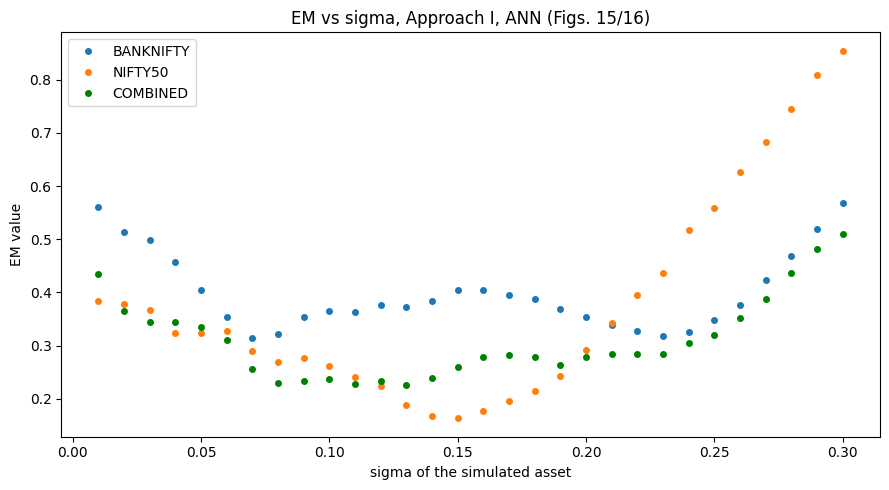

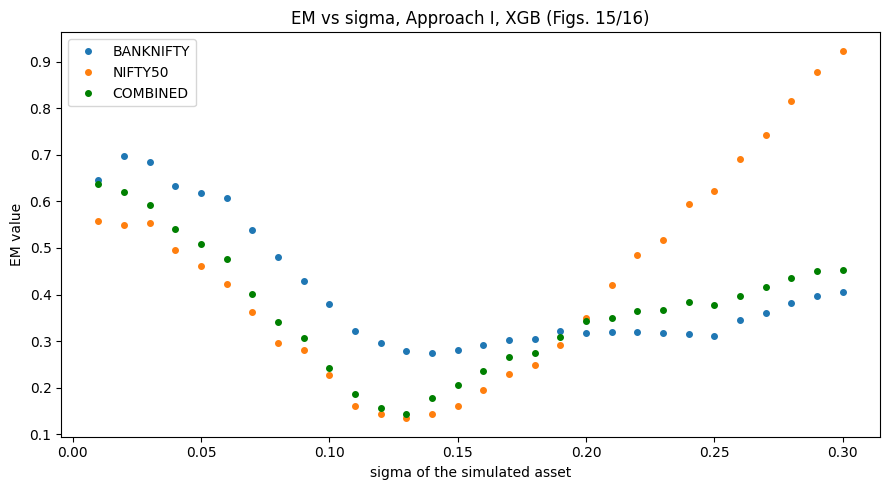

=== Error Minimizing Volatility (EMV) ===
  model trained_on   EMV  min_EM
0   ANN  BANKNIFTY  0.07   0.314
1   ANN    NIFTY50  0.15   0.163
2   ANN   COMBINED  0.13   0.226
3   XGB  BANKNIFTY  0.14   0.275
4   XGB    NIFTY50  0.13   0.135
5   XGB   COMBINED  0.13   0.144


In [26]:
SIGMA_GRID = np.round(np.arange(0.01, 0.31, 0.01), 2)
SIM_DAYS = 500
SIM_MU = 0.1
SIM_TTM_DAYS = [10, 25, 40]
SIM_MONEYNESS = [0.98, 1.00, 1.02]     # stays inside the 0.04 near-ATM band


def simulate_gbm_close(sigma, n_days=SIM_DAYS, mu=SIM_MU, S0=10000.0, seed=0):
    rng = np.random.default_rng(seed)
    dt = 1 / 252.0
    z = rng.standard_normal(n_days + LOOKBACK)
    lr = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    return S0 * np.exp(np.cumsum(lr))


def rolling_order_stats(close, lookback=LOOKBACK):
    n = len(close)
    idx = np.arange(lookback)[None, :] + np.arange(n - lookback + 1)[:, None]
    lr = np.diff(np.log(close[idx]), axis=1)
    return np.sort(lr, axis=1), close[idx[:, -1]]


def simulated_approach1_set(sigma, rate_pct, seed=0):
    close = simulate_gbm_close(sigma, seed=seed)
    os_mat, spot_at_t = rolling_order_stats(close)

    blocks, labels = [], []
    for ttm in SIM_TTM_DAYS:
        for m in SIM_MONEYNESS:
            K = spot_at_t / m
            T = ttm / 365.0
            price = black_scholes_call(spot_at_t, K, T, rate_pct / 100, sigma)
            X = pd.DataFrame(os_mat, columns=[f'os_close_{i+1}' for i in range(os_mat.shape[1])])
            X['moneyness'] = spot_at_t / K
            X['time_to_maturity'] = float(ttm)
            X['interest_rate'] = rate_pct
            blocks.append(X)
            labels.append(price_to_bin(price, K))
    return pd.concat(blocks, ignore_index=True), np.concatenate(labels)


def em_vs_sigma(bundle, rate_pct, model='ann', seed=0):
    ems = []
    for s in SIGMA_GRID:
        X, y = simulated_approach1_set(s, rate_pct, seed=seed)
        pred = predict_bins(bundle, X[bundle['columns']].values, model)
        ems.append(error_metric_EM(y, pred))
    return np.array(ems)


rate_pct = float(np.median(np.concatenate([DATA[n]['risk_free_rate'].values for n in DATA])))
print(f"Using r = {rate_pct:.2f}% for the simulated contracts")

EMV_ROWS = []
for model in ('ann', 'xgb'):
    plt.figure(figsize=(9, 5))
    for name in DATA:
        ems = em_vs_sigma(BUNDLES[(name, 'Approach I')], rate_pct, model)
        plt.plot(SIGMA_GRID, ems, 'o', ms=4, label=name)
        EMV_ROWS.append({'model': model.upper(), 'trained_on': name,
                         'EMV': SIGMA_GRID[int(np.argmin(ems))], 'min_EM': ems.min()})
    if MULTI_ASSET:
        ems = em_vs_sigma(COMBINED_BUNDLES['Approach I'], rate_pct, model)
        plt.plot(SIGMA_GRID, ems, 'o', ms=4, color='green', label='COMBINED')
        EMV_ROWS.append({'model': model.upper(), 'trained_on': 'COMBINED',
                         'EMV': SIGMA_GRID[int(np.argmin(ems))], 'min_EM': ems.min()})
    plt.xlabel('sigma of the simulated asset'); plt.ylabel('EM value')
    plt.title(f'EM vs sigma, Approach I, {model.upper()} (Figs. 15/16)')
    plt.legend(); plt.tight_layout(); plt.show()

emv_table = pd.DataFrame(EMV_ROWS).round(3)
print("=== Error Minimizing Volatility (EMV) ===")
print(emv_table)

## Experiment 13 — Implied and historical volatility by asset (Table 10)

The EMV above should line up with these numbers; that is what tells you the EMV is a property of the
training data rather than a coincidence.

In [27]:
def iv_hist_vol_summary(name, max_rows=8000):
    d = DATA[name]
    if len(d) > max_rows:
        d = d.iloc[np.linspace(0, len(d)-1, max_rows).astype(int)]
    iv = iv_series(d['close'].values, d['underlying'].values, d['strike'].values,
                   d['time_to_maturity_yrs'].values, d['risk_free_rate'].values / 100)
    iv = iv[np.isfinite(iv)]
    mode = pd.Series(np.round(iv, 2)).value_counts().idxmax() if len(iv) else np.nan
    return {'asset': name, 'IV_mean': np.mean(iv), 'IV_median': np.median(iv), 'IV_mode': mode,
            'Historical_Vol': d['hist_vol'].mean()}

vol_table = pd.DataFrame([iv_hist_vol_summary(n) for n in DATA]).set_index('asset').round(3)
print("=== Table 10: IV and historical volatility ===")
print(vol_table)

=== Table 10: IV and historical volatility ===
           IV_mean  IV_median  IV_mode  Historical_Vol
asset                                                 
BANKNIFTY    0.186      0.174     0.12           0.164
NIFTY50      0.147      0.139     0.14           0.129


## Experiment 14 — Regime-shift stress test (Table 11 and Fig. 17)

The paper's COVID experiment: take models trained on the earlier calm period and score them on a
later window whose return distribution has shifted, comparing single-asset training, combined
training, and Black-Scholes. A Q-Q plot of the two periods shows how big the shift is.

Stress window: 2025-06-03 to 2026-06-25


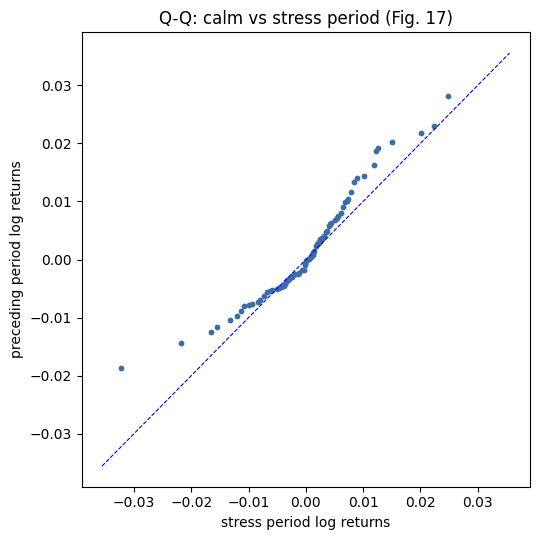

In [28]:
d0 = DATA[list(DATA)[0]]
dates_all = np.sort(d0['date'].unique())
if STRESS_START is None or STRESS_END is None:
    stress_start = pd.Timestamp(dates_all[int(len(dates_all) * 0.80)])
    stress_end = pd.Timestamp(dates_all[-1])
else:
    stress_start, stress_end = pd.Timestamp(STRESS_START), pd.Timestamp(STRESS_END)
print(f"Stress window: {stress_start.date()} to {stress_end.date()}")

# --- Fig. 17: Q-Q of the calm period vs the stress period -----------------
calm_end = stress_start - pd.Timedelta(days=1)
spot0 = load_spot(ASSET_FILES[list(DATA)[0]]['spot'])
spot0 = spot0.dropna(subset=['spot_close'])
calm = spot0[(spot0['date'] < calm_end) & (spot0['date'] >= calm_end - pd.Timedelta(days=120))]
stress = spot0[(spot0['date'] >= stress_start) & (spot0['date'] <= stress_end)]
lr_calm = np.diff(np.log(calm['spot_close'].values))
lr_stress = np.diff(np.log(stress['spot_close'].values))

if len(lr_calm) > 5 and len(lr_stress) > 5:
    n = min(len(lr_calm), len(lr_stress))
    qc = np.quantile(lr_calm, np.linspace(0.01, 0.99, n))
    qs = np.quantile(lr_stress, np.linspace(0.01, 0.99, n))
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(qs, qc, s=10, color='#3b6ea5')
    lim = max(np.abs(np.concatenate([qc, qs]))) * 1.1
    plt.plot([-lim, lim], [-lim, lim], 'b--', lw=0.8)
    plt.xlabel('stress period log returns'); plt.ylabel('preceding period log returns')
    plt.title('Q-Q: calm vs stress period (Fig. 17)')
    plt.tight_layout(); plt.show()

In [29]:
STRESS_APPROACH = 'Approach III'
stress_rows = []

for name in DATA:
    d = DATA[name]
    mask = ((d['date'] >= stress_start) & (d['date'] <= stress_end)).values
    if mask.sum() == 0:
        print(f"[{name}] no rows in the stress window, skipping"); continue

    X_st, y_st, _ = split_xy(FEATURES[name][STRESS_APPROACH], mask)

    for model in ('ann', 'xgb'):
        pred = predict_bins(BUNDLES[(name, STRESS_APPROACH)], X_st, model)
        stress_rows.append({'test_asset': name, 'train_dataset': name, 'model': model.upper(),
                            'EM': error_metric_EM(y_st, pred),
                            'rho': inaccuracy_metric_rho(y_st, pred)})

    if MULTI_ASSET:
        for model in ('ann', 'xgb'):
            pred = predict_bins(COMBINED_BUNDLES[STRESS_APPROACH], X_st, model)
            stress_rows.append({'test_asset': name, 'train_dataset': 'COMBINED',
                                'model': model.upper(),
                                'EM': error_metric_EM(y_st, pred),
                                'rho': inaccuracy_metric_rho(y_st, pred)})

    _, bs_m = bs_benchmark(d, mask)
    stress_rows.append({'test_asset': name, 'train_dataset': 'B-S pricing', 'model': '-',
                        'EM': bs_m['EM'], 'rho': bs_m['rho']})

stress_table = (pd.DataFrame(stress_rows)
                .set_index(['test_asset', 'train_dataset', 'model'])
                .round(3).sort_index())
print("=== Table 11: performance on the stress window ===")
print(stress_table)
print("\nCompare against the ordinary test-set numbers in Experiment 1 —")
print("a large gap is the paper's 'historical vs implied volatility' effect.")

=== Table 11: performance on the stress window ===
                                   EM    rho
test_asset train_dataset model              
BANKNIFTY  B-S pricing   -      0.320  0.460
           BANKNIFTY     ANN    0.237  0.340
                         XGB    0.176  0.236
           COMBINED      ANN    0.177  0.243
                         XGB    0.157  0.211
NIFTY50    B-S pricing   -      0.219  0.329
           COMBINED      ANN    0.147  0.197
                         XGB    0.131  0.159
           NIFTY50       ANN    0.150  0.203
                         XGB    0.125  0.155

Compare against the ordinary test-set numbers in Experiment 1 —
a large gap is the paper's 'historical vs implied volatility' effect.


## Summary — everything in one place

In [30]:
print("=" * 78)
print("1. SINGLE-ASSET MODELS (Tables 4/5)"); print(single_asset_results)
print("\n2. ENSEMBLE (Tables 6/7)"); print(ensemble_results)
print("\n3. BLACK-SCHOLES BENCHMARK"); print(bs_table)
print("\n5. EM vs BIN WIDTH (Figs. 4/5)")
for name, res in binwidth_results.items():
    best = res.loc[res['EM'].idxmin()]
    print(f"   [{name}] lowest EM {best['EM']:.3f} at width {best['bin_width']:g}; "
          f"EM at width 0.1 = {res.loc[(res['bin_width']-0.1).abs().idxmin(), 'EM']:.3f}")
print("\n6. PREDICTION BAND COVERAGE (Fig. 11)"); print(cdf_report[['P(|err|<=2)', 'P(|err|<=5)']])
print("\n7. IV BAND ERROR (Figs. 12/18)")
for name, v in IV_BANDS.items():
    print(f"   [{name}] {v['band_error']:.3f}")
print("\n8. BIAS CHECK (Remark 5.2)"); print(bias_report[['tls_slope', 'tls_intercept', 'mean_signed_error']])
if MULTI_ASSET:
    print("\n10. PORTABILITY (Table 8)"); print(portability)
    print("\n11. COMBINED TRAINING (Table 9)"); print(combined)
print("\n12. EMV (Figs. 15/16)"); print(emv_table)
print("\n13. IV / HISTORICAL VOL (Table 10)"); print(vol_table)
print("\n14. STRESS WINDOW (Table 11)"); print(stress_table)
print("=" * 78)

1. SINGLE-ASSET MODELS (Tables 4/5)
                        EM_ANN  EM_XGB  rho_ANN  rho_XGB
asset     approach                                      
BANKNIFTY Approach I     0.344   0.305    0.461    0.392
          Approach II    0.305   0.276    0.434    0.357
          Approach III   0.245   0.187    0.356    0.257
NIFTY50   Approach I     0.190   0.152    0.279    0.199
          Approach II    0.193   0.168    0.298    0.224
          Approach III   0.157   0.135    0.221    0.174

2. ENSEMBLE (Tables 6/7)
                           EM    rho
asset     approach                  
BANKNIFTY Approach I    0.299  0.442
          Approach II   0.273  0.401
          Approach III  0.192  0.300
NIFTY50   Approach I    0.152  0.228
          Approach II   0.164  0.258
          Approach III  0.131  0.193

3. BLACK-SCHOLES BENCHMARK
              EM    rho
BANKNIFTY  0.313  0.470
NIFTY50    0.222  0.337

5. EM vs BIN WIDTH (Figs. 4/5)
   [BANKNIFTY] lowest EM 0.273 at width 1; EM at width